# ResNet50, MobileNetV2, and Hybrid Model Comparison


In [1]:
# Set deterministic-operation flags before importing TensorFlow.
import os
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

import json
import random
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 0.001
DROPOUT_RATE = 0.3
EARLY_STOPPING_PATIENCE = 7
NUM_PARALLEL_CALLS = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: True


In [2]:
# Keep the reference notebook's train/valid/test directory layout.
DATASET_ROOT = Path("/kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4")
TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR = DATASET_ROOT / "valid"
TEST_DIR = DATASET_ROOT / "test"

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = Path("/kaggle/working/Lung_Cancer_Three_Model_Comparison") / f"run_{RUN_ID}"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
GRAPH_DIR = RUN_DIR / "graphs"
for output_dir in (CHECKPOINT_DIR, GRAPH_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

for split_name, split_dir in (("train", TRAIN_DIR), ("validation", VAL_DIR), ("test", TEST_DIR)):
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Missing {split_name} directory: {split_dir}")

class_names = sorted(path.name for path in TRAIN_DIR.iterdir() if path.is_dir())
if len(class_names) < 2:
    raise ValueError(f"Expected at least two class folders, found: {class_names}")
for split_name, split_dir in (("validation", VAL_DIR), ("test", TEST_DIR)):
    split_classes = sorted(path.name for path in split_dir.iterdir() if path.is_dir())
    if split_classes != class_names:
        raise ValueError(f"Class folders differ in {split_name}: {split_classes}")

NUM_CLASSES = len(class_names)
print("Dataset:", DATASET_ROOT)
print("Classes:", class_names)
print("Results:", RUN_DIR)

# Resizing, class order, and label format are identical across all splits.
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=class_names, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, label_mode="int", shuffle=True, seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, class_names=class_names, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, label_mode="int", shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=class_names, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, label_mode="int", shuffle=False,
)

data_options = tf.data.Options()
data_options.experimental_deterministic = True
train_ds = train_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)
val_ds = val_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)
test_ds = test_ds.with_options(data_options).prefetch(NUM_PARALLEL_CALLS)

print("Class order verified for all splits:", class_names)

Dataset: /kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4
Classes: ['Benign', 'Malignant', 'Normal']
Results: /kaggle/working/Lung_Cancer_Three_Model_Comparison/run_20261127_154851
Found 2221 files belonging to 3 classes.
Found 289 files belonging to 3 classes.
Found 292 files belonging to 3 classes.
Class order verified for all splits: ['Benign', 'Malignant', 'Normal']


In [3]:
# Each backbone uses its matching ImageNet preprocessing, as in the reference.
BACKBONES = {
    "ResNet50": (ResNet50, resnet_preprocess),
    "MobileNetV2": (MobileNetV2, mobilenet_preprocess),
}
MODEL_NAMES = ["ResNet50", "MobileNetV2", "Hybrid_MobileNetV2_ResNet50"]


def make_backbone(model_name):
    constructor, preprocess_function = BACKBONES[model_name]
    backbone = constructor(
        weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3)
    )
    backbone.trainable = False
    return backbone, preprocess_function


def build_model(model_name):
    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")

    if model_name in BACKBONES:
        backbone, preprocess_function = make_backbone(model_name)
        x = layers.Lambda(preprocess_function, name=f"{model_name}_preprocessing")(inputs)
        feature_map = backbone(x, training=False)
        x = layers.GlobalAveragePooling2D(name="global_average_pooling")(feature_map)
        x = layers.Dropout(DROPOUT_RATE, name="classifier_dropout")(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)
        model = models.Model(inputs, outputs, name=f"{model_name}_classifier")

    elif model_name == "Hybrid_MobileNetV2_ResNet50":
        branch_features = []
        for branch_name in ("MobileNetV2", "ResNet50"):
            backbone, preprocess_function = make_backbone(branch_name)
            x = layers.Lambda(
                preprocess_function, name=f"{branch_name}_preprocessing"
            )(inputs)
            feature_map = backbone(x, training=False)
            branch_features.append(
                layers.GlobalAveragePooling2D(name=f"{branch_name}_gap")(feature_map)
            )

        x = layers.Concatenate(name="feature_fusion")(branch_features)
        x = layers.Dropout(DROPOUT_RATE, name="fusion_dropout")(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)
        model = models.Model(inputs, outputs, name=model_name)
    else:
        raise ValueError(f"Unsupported model name: {model_name}")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("Models:", MODEL_NAMES)


Models: ['ResNet50', 'MobileNetV2', 'Hybrid_MobileNetV2_ResNet50']


In [4]:
# Train each model with the same datasets, optimizer, loss, callbacks, and limits.
trained_models = {}
trained_histories = {}
training_seconds = {}

for model_name in MODEL_NAMES:
    print("\n" + "=" * 60 + "\nTraining:", model_name)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(model_name)
    model.summary()

    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.weights.h5"
    callbacks = [
        EarlyStopping(
            monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True, verbose=1,
        ),
        ModelCheckpoint(
            filepath=str(checkpoint_path), monitor="val_loss",
            save_best_only=True, save_weights_only=True, verbose=1,
        ),
    ]

    started = time.perf_counter()
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS,
        callbacks=callbacks, verbose=1,
    )
    training_seconds[model_name] = time.perf_counter() - started
    model.load_weights(checkpoint_path)
    trained_models[model_name] = model
    trained_histories[model_name] = history
    print(f"Training time: {training_seconds[model_name] / 60:.2f} minutes")


Training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ResNet50_preprocessing (Lambda) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

... (9 outputs left out)

 Total params: 25,855,683 (98.63 MB)

 Trainable params: 9,987 (39.01 KB)

 Non-trainable params: 25,845,696 (98.59 MB)

Epoch 1/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.7356 - loss: 0.6557
Epoch 1: val_loss improved from None to 0.24241, saving model to /kaggle/working/Lung_Cancer_Three_Model_Comparison/run_20261127_154851/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Lung_Cancer_Three_Model_Comparison/run_20261127_154851/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weights.h5
139/139 ━━━━━━━━━━━━━━━━━━━━ 30s 149ms/step - accuracy: 0.8244 - loss: 0.4255 - val_accuracy: 0.9066 - val_loss: 0.2424
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.8881 - loss: 0.2500
Epoch 2: val_loss improved from 0.24241 to 0.20955, saving model to /kaggle/working/Lung_Cancer_Three_Model_Comparison/run_20261127_154851/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/Lung_Cancer_Three_Model_Comparison/run_20261127_154851/checkpoints/Hybrid_MobileNetV2_ResNet50_best.weig

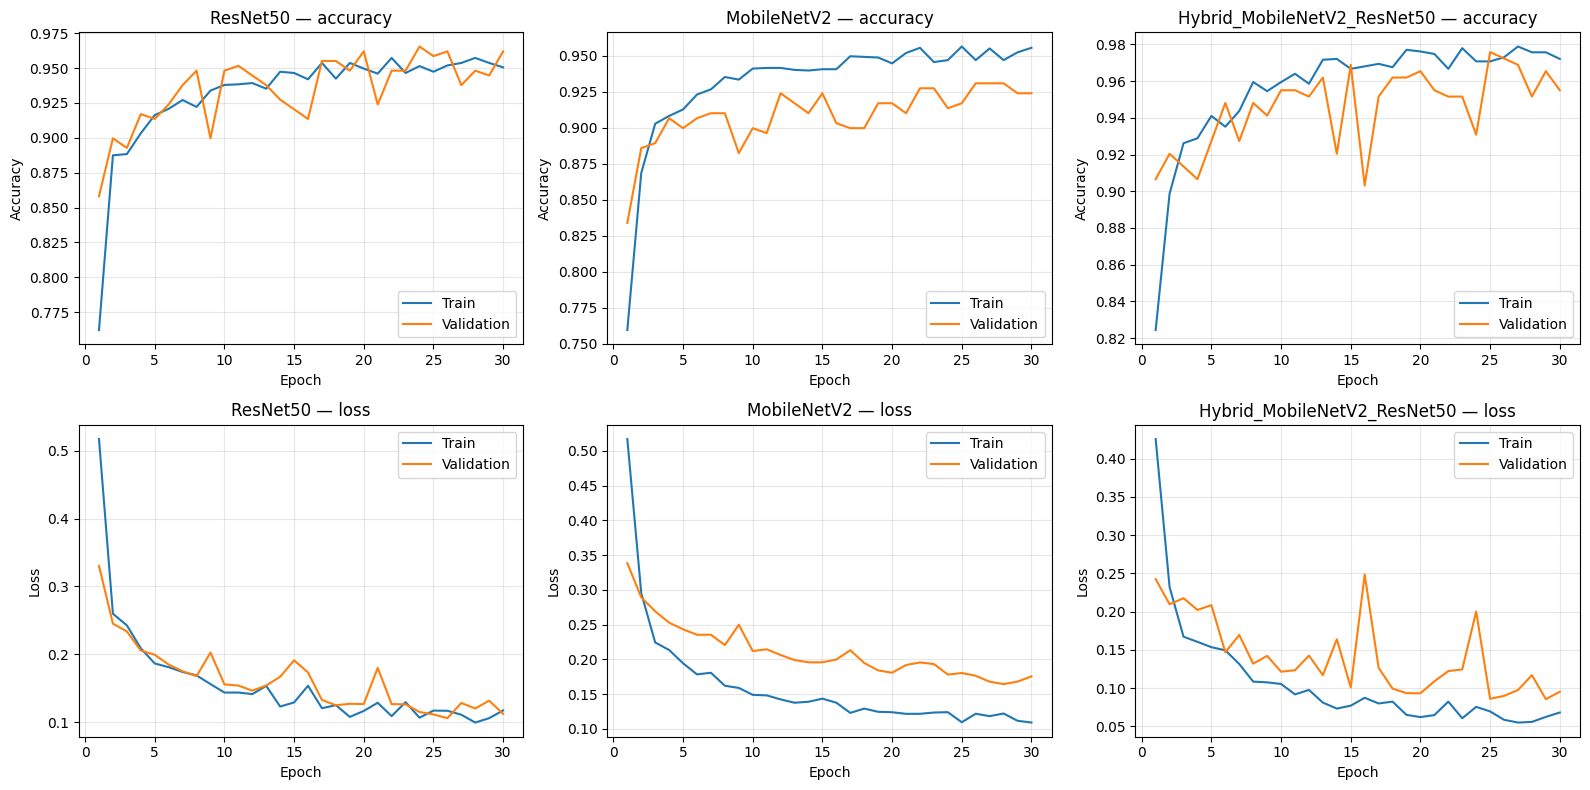

In [5]:
# Compare training and validation learning curves in the same model order.
fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(16, 8))
for column, model_name in enumerate(MODEL_NAMES):
    history = trained_histories[model_name].history
    epochs_seen = range(1, len(history["accuracy"]) + 1)

    axes[0, column].plot(epochs_seen, history["accuracy"], label="Train")
    axes[0, column].plot(epochs_seen, history["val_accuracy"], label="Validation")
    axes[0, column].set_title(f"{model_name} — accuracy")
    axes[0, column].set_xlabel("Epoch")
    axes[0, column].set_ylabel("Accuracy")
    axes[0, column].grid(alpha=0.3)
    axes[0, column].legend()

    axes[1, column].plot(epochs_seen, history["loss"], label="Train")
    axes[1, column].plot(epochs_seen, history["val_loss"], label="Validation")
    axes[1, column].set_title(f"{model_name} — loss")
    axes[1, column].set_xlabel("Epoch")
    axes[1, column].set_ylabel("Loss")
    axes[1, column].grid(alpha=0.3)
    axes[1, column].legend()

fig.tight_layout()
fig.savefig(GRAPH_DIR / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

,Validation Macro F1 (%),Accuracy (%),Precision - Macro (%),Recall / Sensitivity - Macro (%),Specificity - Macro (%),F1-score - Macro (%),ROC-AUC - Macro,Average Precision - Macro,Training Time (minutes)
Model,,,,,,,,,
ResNet50,96.228,95.205,95.237,95.237,97.203,95.237,0.988,0.979,6.808
MobileNetV2,93.168,92.466,92.669,92.256,95.507,92.456,0.980,0.961,2.604
Hybrid_MobileNetV2_ResNet50,96.610,95.205,95.065,95.495,97.301,95.273,0.991,0.986,8.472


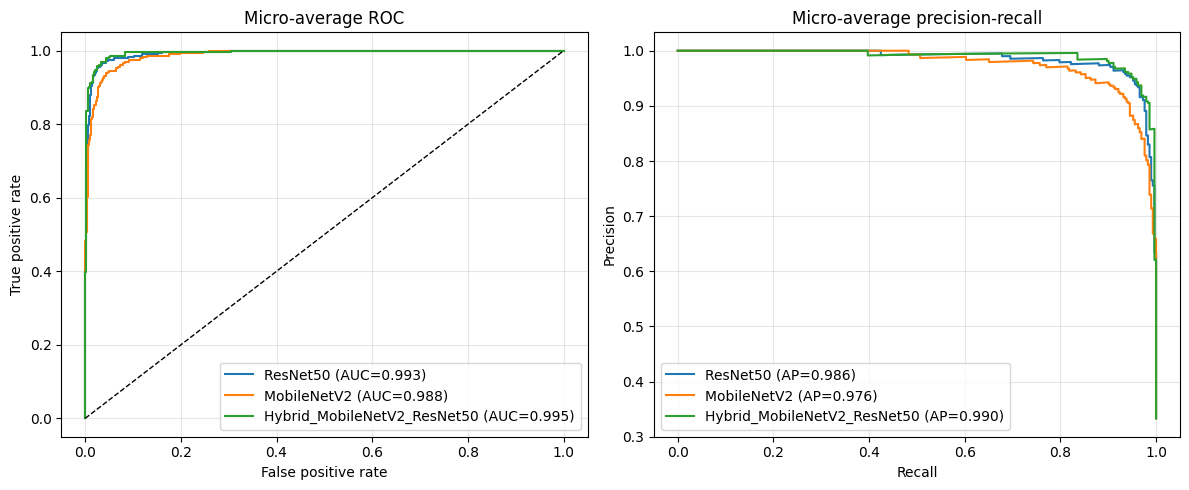

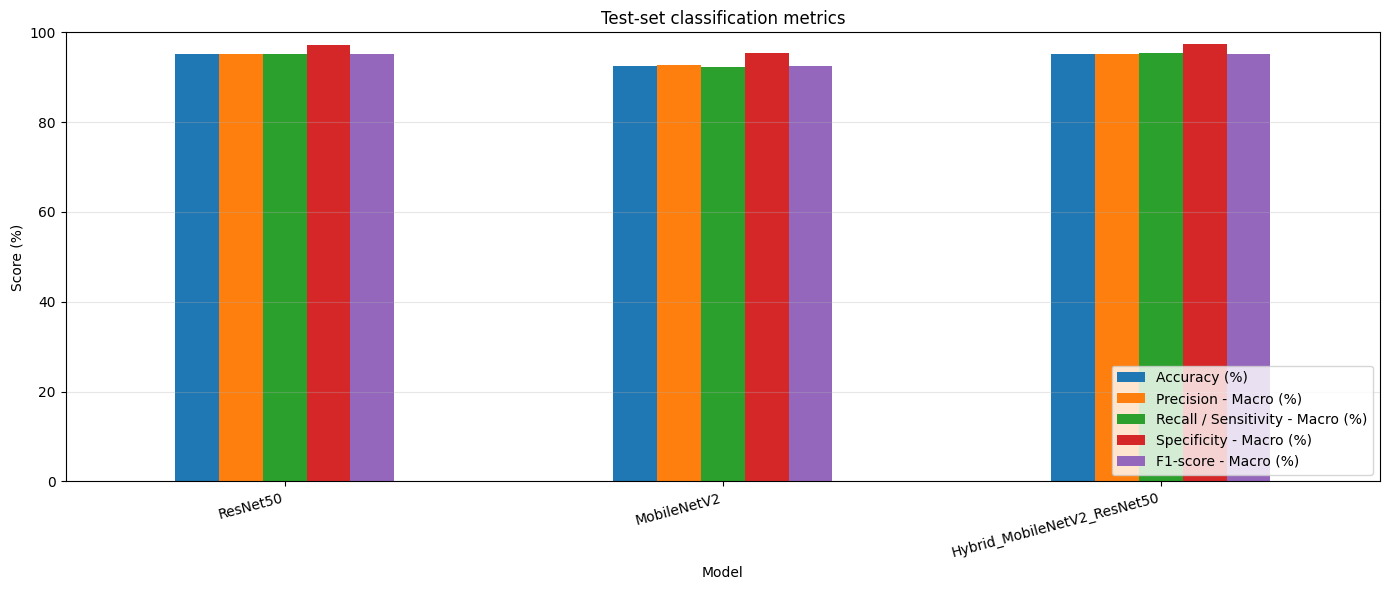


ResNet50: per-class test metrics


,precision,recall,f1-score,support
Benign,0.901,0.901,0.901,71.0
Malignant,0.956,0.956,0.956,158.0
Normal,1.000,1.000,1.000,63.0



MobileNetV2: per-class test metrics


,precision,recall,f1-score,support
Benign,0.855,0.831,0.843,71.0
Malignant,0.925,0.937,0.931,158.0
Normal,1.000,1.000,1.000,63.0



Hybrid_MobileNetV2_ResNet50: per-class test metrics


,precision,recall,f1-score,support
Benign,0.890,0.915,0.903,71.0
Malignant,0.962,0.949,0.955,158.0
Normal,1.000,1.000,1.000,63.0


In [6]:
# Evaluate once on the same ordered validation and test datasets.
def collect_labels(dataset):
    return np.concatenate([labels.numpy() for _, labels in dataset]).astype(int)


def macro_specificity(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    scores = []
    for class_index in range(NUM_CLASSES):
        tp = matrix[class_index, class_index]
        fn = matrix[class_index, :].sum() - tp
        fp = matrix[:, class_index].sum() - tp
        tn = matrix.sum() - tp - fn - fp
        scores.append(tn / (tn + fp) if (tn + fp) else np.nan)
    return float(np.nanmean(scores))


y_val = collect_labels(val_ds)
y_test = collect_labels(test_ds)
for split_name, labels in (("validation", y_val), ("test", y_test)):
    if set(np.unique(labels)) != set(range(NUM_CLASSES)):
        raise ValueError(f"{split_name} must contain every class for comparable macro metrics.")
val_probabilities = {}
test_probabilities = {}
comparison_rows = []
per_class_reports = {}

for model_name, model in trained_models.items():
    val_probabilities[model_name] = model.predict(val_ds, verbose=0)
    test_probabilities[model_name] = model.predict(test_ds, verbose=0)
    val_predictions = np.argmax(val_probabilities[model_name], axis=1)
    test_predictions = np.argmax(test_probabilities[model_name], axis=1)
    test_one_hot = np.eye(NUM_CLASSES)[y_test]

    if NUM_CLASSES == 2:
        roc_auc = roc_auc_score(y_test, test_probabilities[model_name][:, 1])
    else:
        roc_auc = roc_auc_score(
            y_test, test_probabilities[model_name],
            labels=np.arange(NUM_CLASSES), multi_class="ovr", average="macro",
        )

    comparison_rows.append({
        "Model": model_name,
        "Validation Macro F1 (%)": 100 * f1_score(
            y_val, val_predictions, average="macro", zero_division=0
        ),
        "Accuracy (%)": 100 * accuracy_score(y_test, test_predictions),
        "Precision - Macro (%)": 100 * precision_score(
            y_test, test_predictions, average="macro", zero_division=0
        ),
        "Recall / Sensitivity - Macro (%)": 100 * recall_score(
            y_test, test_predictions, average="macro", zero_division=0
        ),
        "Specificity - Macro (%)": 100 * macro_specificity(y_test, test_predictions),
        "F1-score - Macro (%)": 100 * f1_score(
            y_test, test_predictions, average="macro", zero_division=0
        ),
        "ROC-AUC - Macro": roc_auc,
        "Average Precision - Macro": average_precision_score(
            test_one_hot, test_probabilities[model_name], average="macro"
        ),
        "Training Time (minutes)": training_seconds[model_name] / 60,
    })
    per_class_reports[model_name] = classification_report(
        y_test, test_predictions, labels=np.arange(NUM_CLASSES),
        target_names=class_names, output_dict=True, zero_division=0,
    )

comparison_df = pd.DataFrame(comparison_rows).set_index("Model").loc[MODEL_NAMES]
display(comparison_df.round(3))

# Micro-averaged ROC and precision-recall curves compare all classes together.
test_one_hot = np.eye(NUM_CLASSES)[y_test]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for model_name in MODEL_NAMES:
    probabilities = test_probabilities[model_name]
    fpr, tpr, _ = roc_curve(test_one_hot.ravel(), probabilities.ravel())
    micro_auc = roc_auc_score(test_one_hot.ravel(), probabilities.ravel())
    axes[0].plot(fpr, tpr, label=f"{model_name} (AUC={micro_auc:.3f})")
    precision_curve, recall_curve, _ = precision_recall_curve(
        test_one_hot.ravel(), probabilities.ravel()
    )
    micro_ap = average_precision_score(test_one_hot.ravel(), probabilities.ravel())
    axes[1].plot(recall_curve, precision_curve, label=f"{model_name} (AP={micro_ap:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(title="Micro-average ROC", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Micro-average precision-recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(GRAPH_DIR / "roc_precision_recall_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Side-by-side chart for the percentage-based test metrics.
metric_columns = [
    "Accuracy (%)", "Precision - Macro (%)", "Recall / Sensitivity - Macro (%)",
    "Specificity - Macro (%)", "F1-score - Macro (%)",
]
ax = comparison_df[metric_columns].plot(kind="bar", figsize=(14, 6), ylim=(0, 100))
ax.set_title("Test-set classification metrics")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "test_metrics_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

for model_name, report in per_class_reports.items():
    print(f"\n{model_name}: per-class test metrics")
    display(pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(3))

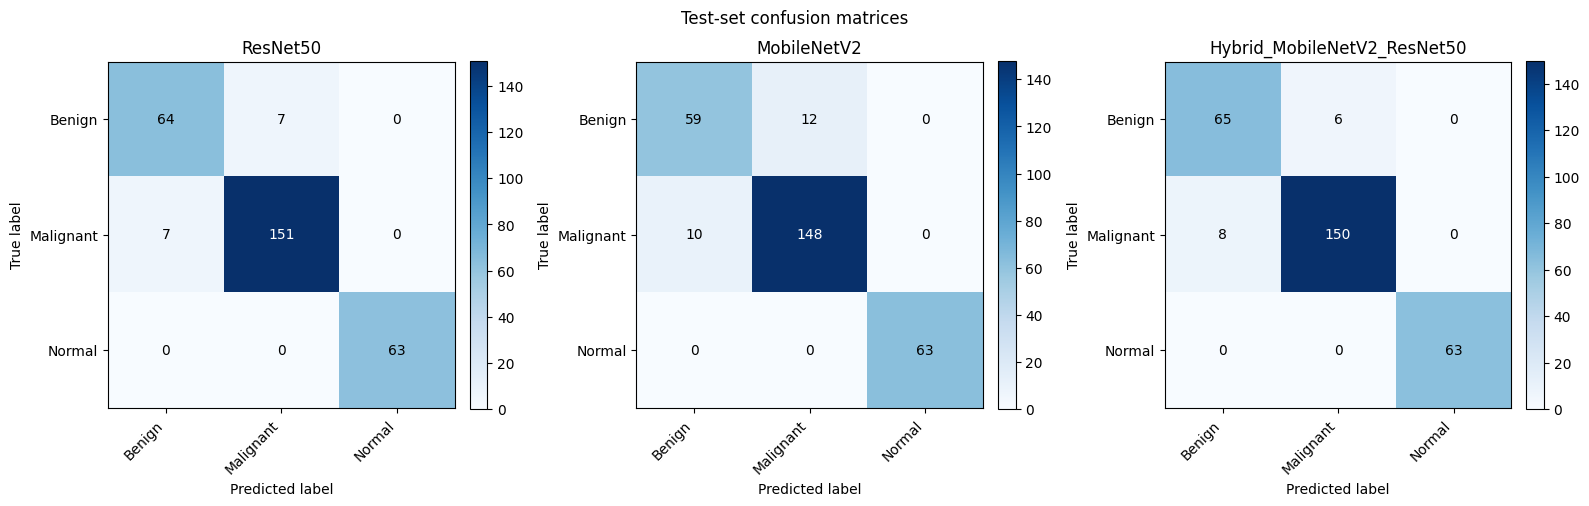

In [7]:
# Confusion matrices share the same test examples and class ordering.
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(16, 5))
for ax, model_name in zip(axes, MODEL_NAMES):
    predictions = np.argmax(test_probabilities[model_name], axis=1)
    matrix = confusion_matrix(y_test, predictions, labels=np.arange(NUM_CLASSES))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(np.arange(NUM_CLASSES), class_names, rotation=45, ha="right")
    ax.set_yticks(np.arange(NUM_CLASSES), class_names)
    threshold = matrix.max() / 2 if matrix.size else 0
    for row in range(NUM_CLASSES):
        for column in range(NUM_CLASSES):
            ax.text(
                column, row, str(matrix[row, column]), ha="center", va="center",
                color="white" if matrix[row, column] > threshold else "black",
            )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Test-set confusion matrices")
fig.tight_layout()
fig.savefig(GRAPH_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

In [8]:
# Fix the XAI examples once; every model receives these exact test images and labels.
XAI_IMAGE_COUNT = 5
xai_images = []
xai_labels = []
for image, label in test_ds.unbatch().take(XAI_IMAGE_COUNT):
    xai_images.append(image.numpy())
    xai_labels.append(int(label.numpy()))
xai_images = np.asarray(xai_images, dtype=np.float32)
xai_labels = np.asarray(xai_labels, dtype=int)
if len(xai_images) != XAI_IMAGE_COUNT:
    print(f"Only {len(xai_images)} test images are available for XAI.")
if len(xai_images) == 0:
    raise ValueError("The test split contains no images for XAI visualization.")

print(f"Using {len(xai_images)} fixed test images for all models.")

Using 5 fixed test images for all models.


In [9]:
# Reusable Grad-CAM and Grad-CAM++ functions for the selected convolutional feature map.
def get_explainer(model_name, model):
    """Build explainer model from trained model's layers to avoid graph tracing issues."""
    if model_name in BACKBONES:
        # For single backbone models, feature map is input to global_average_pooling layer
        gap_layer = model.get_layer("global_average_pooling")
        feature_map_tensor = gap_layer.input
    elif model_name == "Hybrid_MobileNetV2_ResNet50":
        # For hybrid, feature map is input to MobileNetV2_gap layer (MobileNetV2 backbone output)
        gap_layer = model.get_layer("MobileNetV2_gap")
        feature_map_tensor = gap_layer.input
    else:
        raise ValueError(f"Unsupported model name: {model_name}")

    return models.Model(
        inputs=model.input,
        outputs=[feature_map_tensor, model.output],
        name=f"{model_name}_explainer",
    )


def make_heatmaps(model_name, model, image, class_index):
    explainer = get_explainer(model_name, model)
    input_tensor = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        feature_maps, predictions = explainer(input_tensor, training=False)
        class_score = predictions[:, class_index]
    gradients = tape.gradient(class_score, feature_maps)
    if gradients is None:
        raise RuntimeError(f"No gradients for the selected layer in {model_name}.")

    # Grad-CAM: average gradients over spatial positions for channel weights.
    gradcam_weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    gradcam = tf.reduce_sum(gradcam_weights * feature_maps, axis=-1)[0]
    gradcam = tf.maximum(gradcam, 0)

    # Grad-CAM++: use first-, second-, and third-order gradient terms.
    squared_gradients = tf.square(gradients)
    cubed_gradients = tf.pow(gradients, 3)
    denominator = 2 * squared_gradients + tf.reduce_sum(
        feature_maps * cubed_gradients, axis=(1, 2), keepdims=True
    )
    alphas = squared_gradients / (denominator + tf.keras.backend.epsilon())
    gradcam_pp_weights = tf.reduce_sum(
        alphas * tf.maximum(gradients, 0), axis=(1, 2), keepdims=True
    )
    gradcam_pp = tf.reduce_sum(gradcam_pp_weights * feature_maps, axis=-1)[0]
    gradcam_pp = tf.maximum(gradcam_pp, 0)

    def resize_and_normalize(heatmap):
        heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE)[..., 0]
        heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())
        return heatmap.numpy()

    return resize_and_normalize(gradcam), resize_and_normalize(gradcam_pp)


def overlay_heatmap(image, heatmap, alpha=0.4):
    image = np.clip(image / 255.0, 0, 1)
    color_map = plt.get_cmap("jet")
    colored_heatmap = color_map(heatmap)[..., :3]
    return np.clip((1 - alpha) * image + alpha * colored_heatmap, 0, 1)


E0000 00:00:1795795646.918256      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1795795654.529684      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

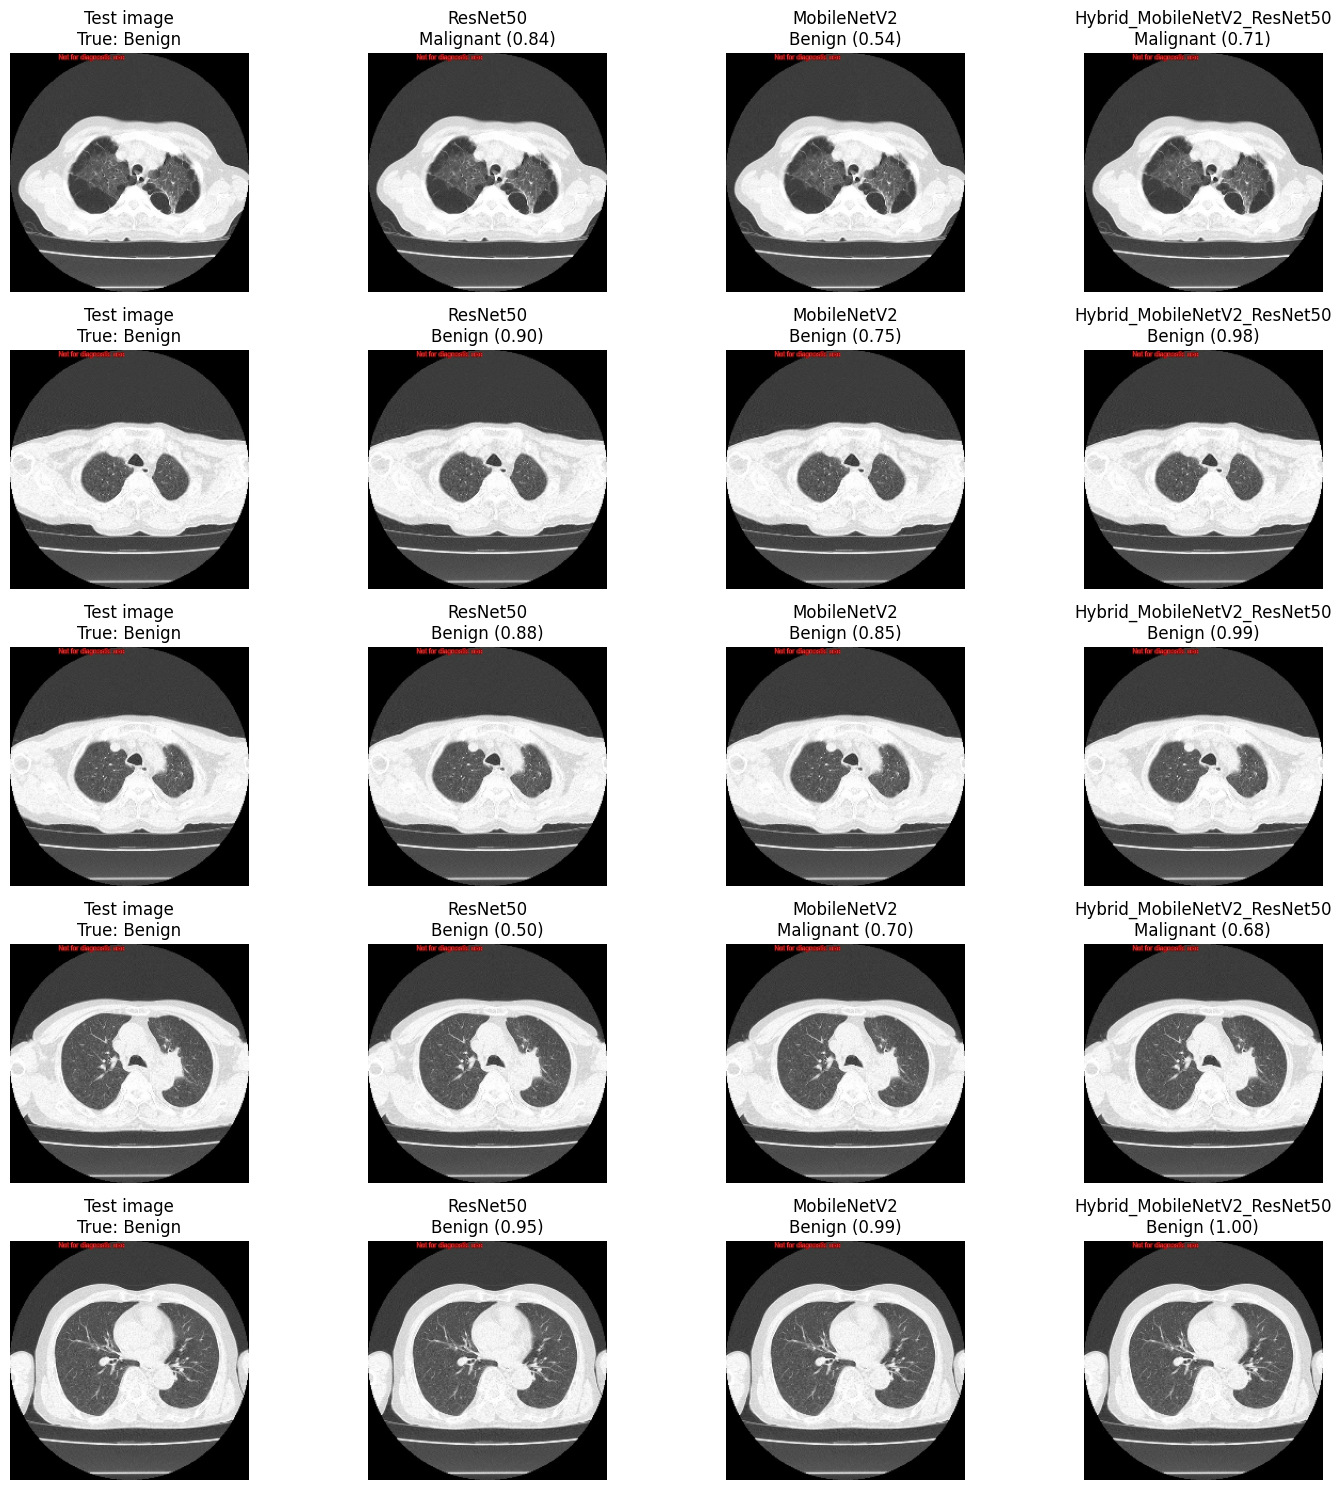

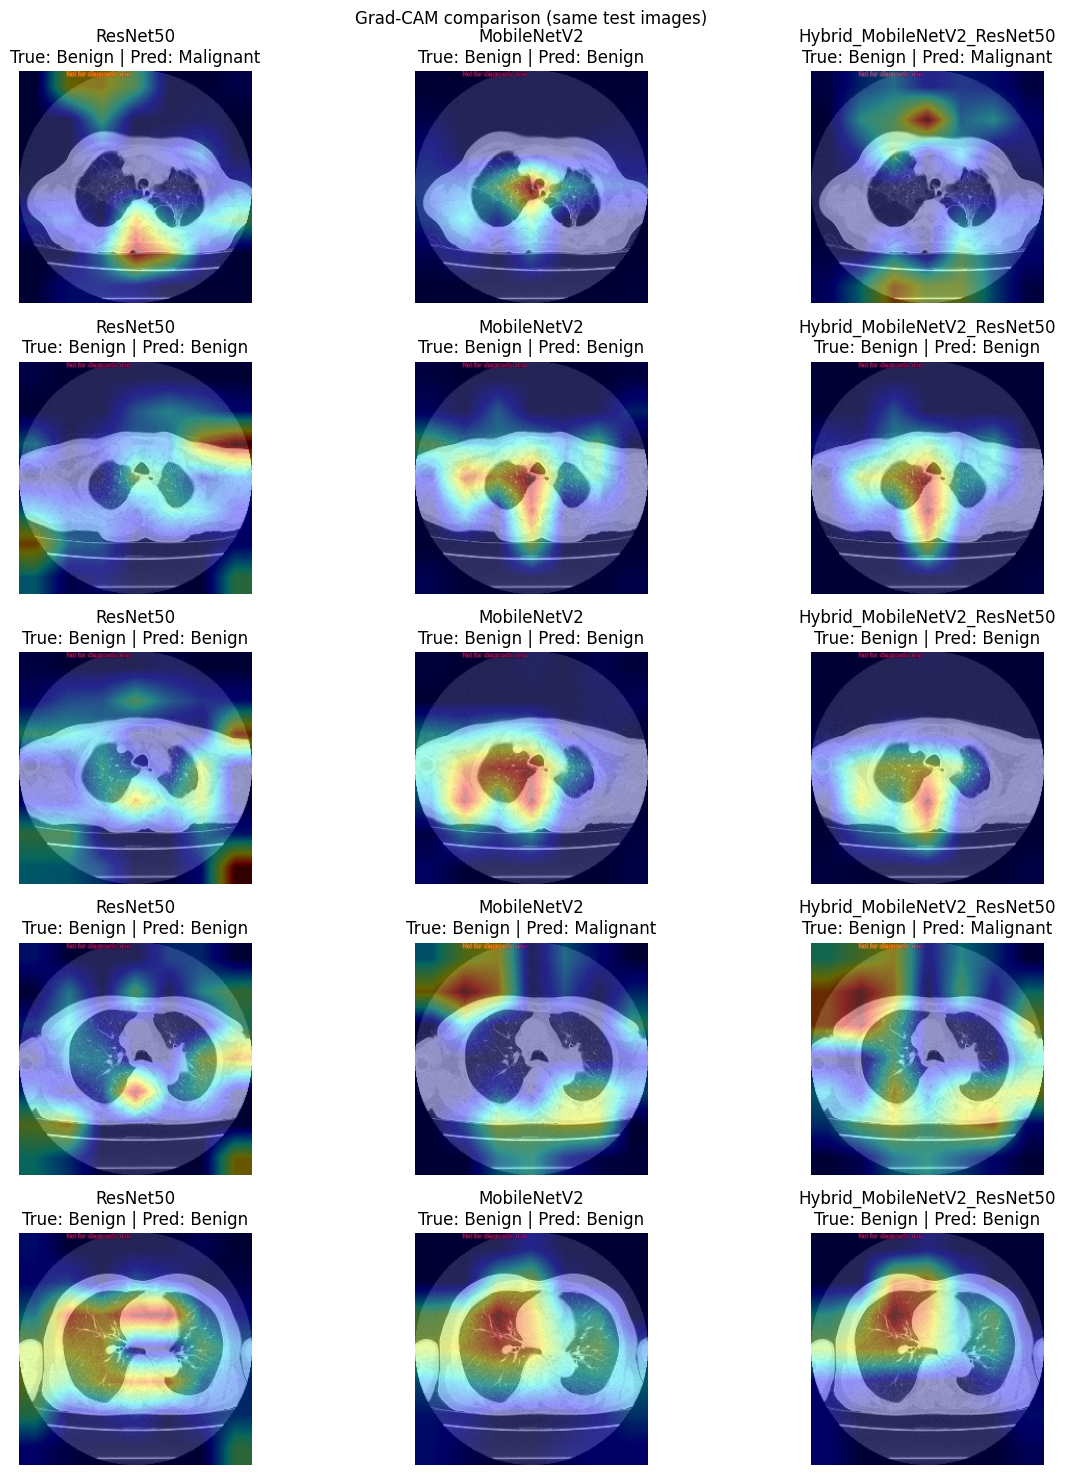

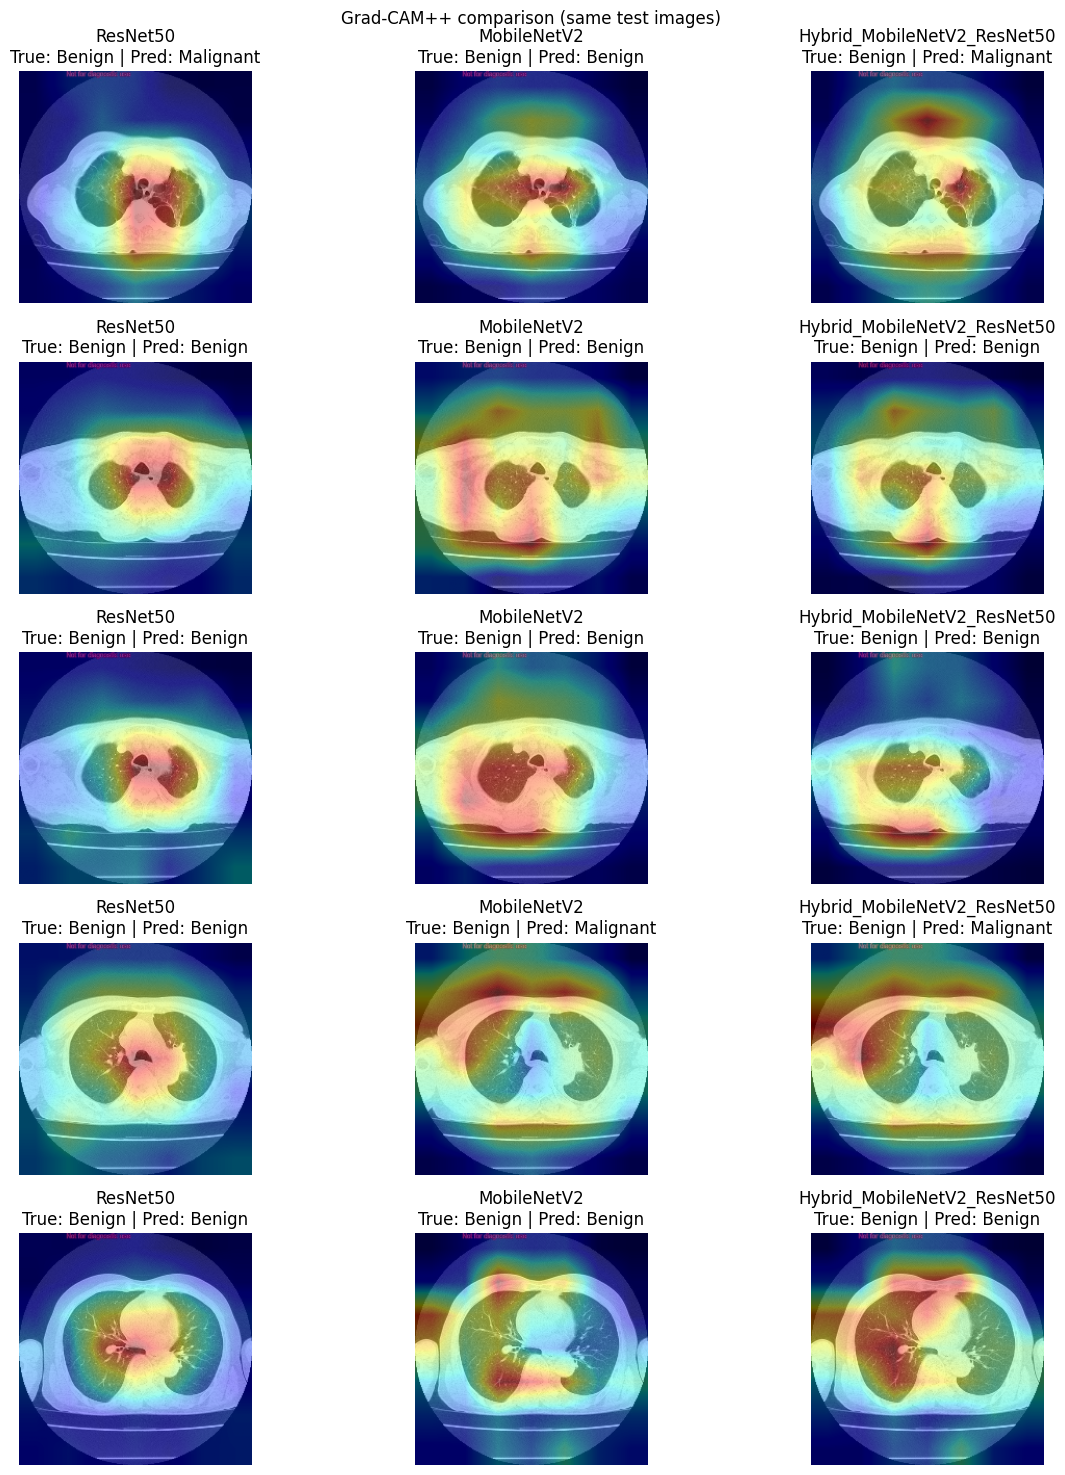

In [10]:
# Compare predictions and explanations for the same fixed test images.
xai_results = {name: {"gradcam": [], "gradcam_pp": []} for name in MODEL_NAMES}
xai_predictions = {}
for model_name, model in trained_models.items():
    probabilities = model.predict(xai_images, verbose=0)
    xai_predictions[model_name] = probabilities
    for image, class_probabilities in zip(xai_images, probabilities):
        predicted_class = int(np.argmax(class_probabilities))
        gradcam, gradcam_pp = make_heatmaps(
            model_name, model, image, predicted_class
        )
        xai_results[model_name]["gradcam"].append(gradcam)
        xai_results[model_name]["gradcam_pp"].append(gradcam_pp)

# Prediction comparison: original image, then each model's predicted class/confidence.
fig, axes = plt.subplots(len(xai_images), len(MODEL_NAMES) + 1, figsize=(15, 3 * len(xai_images)), squeeze=False)
for row, (image, true_index) in enumerate(zip(xai_images, xai_labels)):
    axes[row, 0].imshow(np.clip(image / 255.0, 0, 1))
    axes[row, 0].set_title(f"Test image\nTrue: {class_names[true_index]}")
    axes[row, 0].axis("off")
    for column, model_name in enumerate(MODEL_NAMES, start=1):
        probabilities = xai_predictions[model_name][row]
        predicted_index = int(np.argmax(probabilities))
        axes[row, column].imshow(np.clip(image / 255.0, 0, 1))
        axes[row, column].set_title(
            f"{model_name}\n{class_names[predicted_index]} ({probabilities[predicted_index]:.2f})"
        )
        axes[row, column].axis("off")
fig.tight_layout()
fig.savefig(GRAPH_DIR / "xai_prediction_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Each row is the same test image; columns compare the three model explanations.
for method, title in (("gradcam", "Grad-CAM"), ("gradcam_pp", "Grad-CAM++")):
    fig, axes = plt.subplots(len(xai_images), len(MODEL_NAMES), figsize=(13, 3 * len(xai_images)), squeeze=False)
    for row, (image, true_index) in enumerate(zip(xai_images, xai_labels)):
        for column, model_name in enumerate(MODEL_NAMES):
            heatmap = xai_results[model_name][method][row]
            predicted_index = int(np.argmax(xai_predictions[model_name][row]))
            axes[row, column].imshow(overlay_heatmap(image, heatmap))
            axes[row, column].set_title(
                f"{model_name}\nTrue: {class_names[true_index]} | "
                f"Pred: {class_names[predicted_index]}"
            )
            axes[row, column].axis("off")
    fig.suptitle(f"{title} comparison (same test images)")
    fig.tight_layout()
    fig.savefig(GRAPH_DIR / f"{method}_comparison.png", dpi=160, bbox_inches="tight")
    plt.show()

In [11]:
# Save the comparable metrics, per-class reports, and experiment settings.
comparison_df.to_csv(RUN_DIR / "model_comparison.csv")
with (RUN_DIR / "per_class_reports.json").open("w") as file:
    json.dump(per_class_reports, file, indent=2)

experiment_config = {
    "seed": SEED,
    "dataset_root": str(DATASET_ROOT),
    "split_directories": {"train": str(TRAIN_DIR), "validation": str(VAL_DIR), "test": str(TEST_DIR)},
    "class_names_in_label_order": class_names,
    "input_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_max": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "dropout_rate": DROPOUT_RATE,
    "early_stopping": {"monitor": "val_loss", "patience": EARLY_STOPPING_PATIENCE},
    "models": MODEL_NAMES,
    "xai_test_images": len(xai_images),
}
with (RUN_DIR / "experiment_config.json").open("w") as file:
    json.dump(experiment_config, file, indent=2)

print("Comparison and graph files saved to:", RUN_DIR)

Comparison and graph files saved to: /kaggle/working/Lung_Cancer_Three_Model_Comparison/run_20261127_154851
